# Transformer Model

# Ablation Study

Train: preprocessed_augmented_dataset_scaled.csv
Val  : validation_set_scaled.csv
Test : test_set_scaled.csv
Shape: (100000, 19, 1) | Classes: 10

Running variant: 0_baseline_exact
Epoch 1/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 45s 14ms/step - accuracy: 0.5446 - loss: 1.6014 - val_accuracy: 0.7688 - val_loss: 1.1753 - learning_rate: 1.5000e-04
Epoch 2/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.7365 - loss: 1.2843 - val_accuracy: 0.7719 - val_loss: 1.1267 - learning_rate: 1.5000e-04
Epoch 3/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.7837 - loss: 1.2119 - val_accuracy: 0.8062 - val_loss: 1.0881 - learning_rate: 1.5000e-04
Epoch 4/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8103 - loss: 1.1676 - val_accuracy: 0.8438 - val_loss: 1.0409 - learning_rate: 1.5000e-04
Epoch 5/40
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8293 - loss: 1.1358 - val_accuracy: 0.8625 - val_loss: 1.0232 - learning_rate: 1.5000e-04
Epoch 6/40
1563/1563 ━━

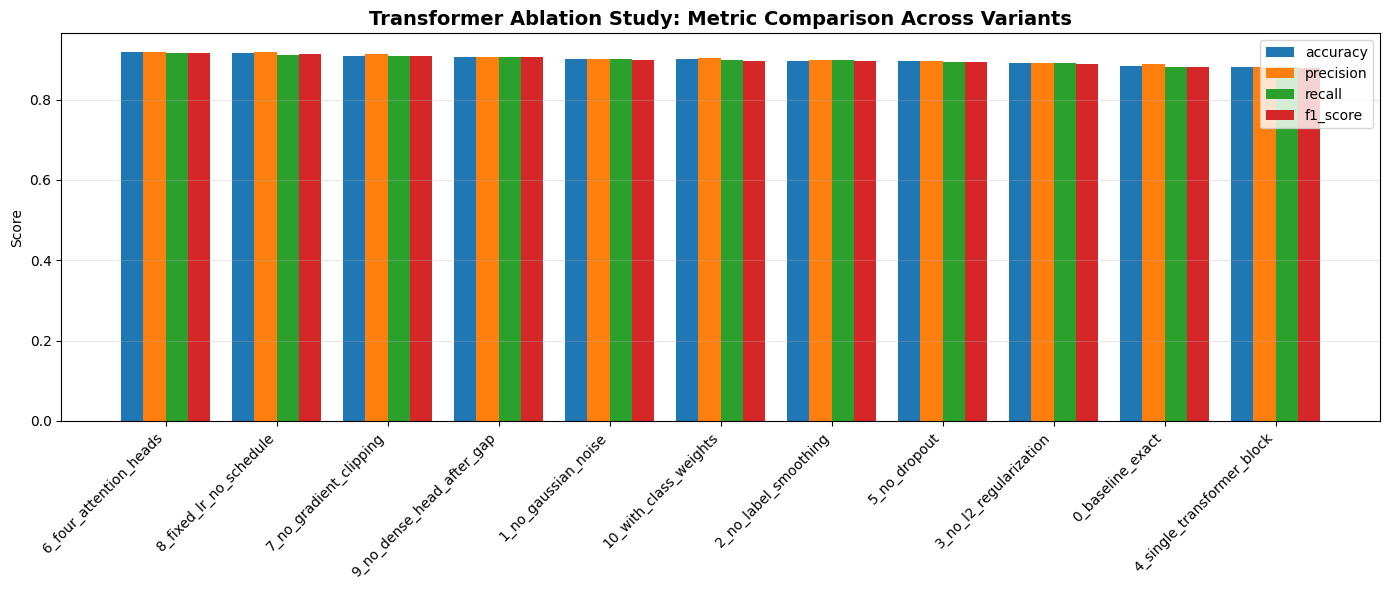

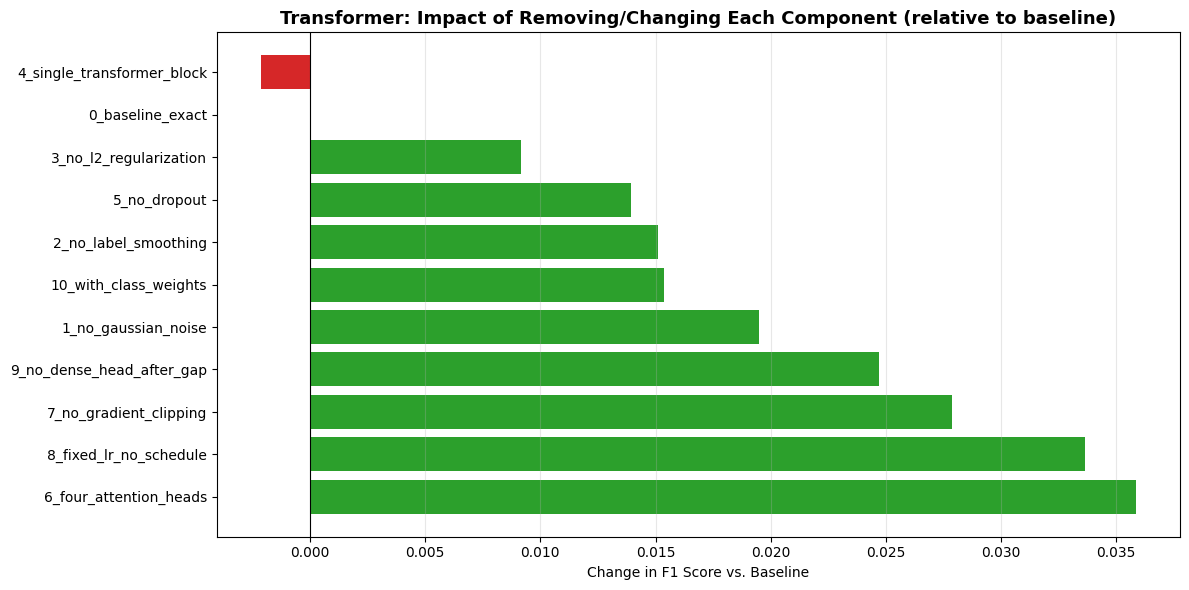

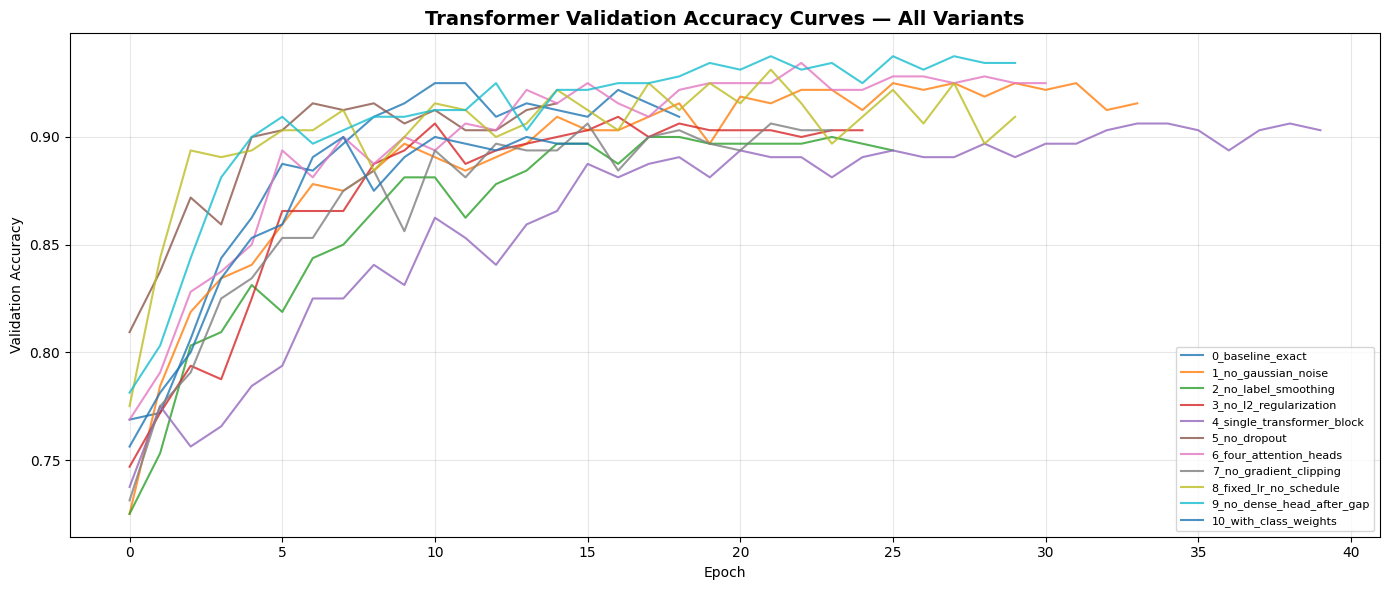


Saved plots: transformer_ablation_metric_comparison.png, transformer_ablation_delta_from_baseline.png, transformer_ablation_val_accuracy_curves.png

SUMMARY: Component impact (F1 delta vs baseline, macro-averaged)
                   variant  f1_delta_vs_baseline  trainable_params
4_single_transformer_block             -0.002143             14250
    3_no_l2_regularization              0.009154             33578
              5_no_dropout              0.013921             33578
      2_no_label_smoothing              0.015091             33578
     10_with_class_weights              0.015383             33578
       1_no_gaussian_noise              0.019488             33578
 9_no_dense_head_after_gap              0.024715             29386
    7_no_gradient_clipping              0.027863             33578
    8_fixed_lr_no_schedule              0.033654             33578
    6_four_attention_heads              0.035865             46154

Most negative delta = component contributes mos

In [ ]:
# ============================================================
# ABLATION STUDY: TRANSFORMER FOR BEARING FAULT DETECTION
# Variants tested:
#   0. Full model (baseline)
#   1. No Gaussian Noise
#   2. No Label Smoothing
#   3. No L2 Regularization
#   4. Single Transformer Block instead of 3 blocks
#   5. No Dropout
#   6. Four Attention Heads instead of Two
#   7. No Gradient Clipping
#   8. Fixed Higher Learning Rate, No ReduceLROnPlateau
#   9. No Dense Classification Head after Global Average Pooling
#  10. With Class Weights for Imbalanced Classes
# ============================================================
# ============================================================

# !pip -q install tensorflow

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.layers import (
    Input, Dense, Dropout, LayerNormalization, MultiHeadAttention,
    Add, GaussianNoise, GlobalAveragePooling1D
)
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Model

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ============================================================
# LOAD DATA
# ============================================================

files_list = os.listdir()

def find_file(keyword):
    matches = [f for f in files_list if keyword in f.lower()]
    return matches[0]

train_file = find_file("augmented")
val_file = find_file("validation")
test_file = find_file("test")

print("Train:", train_file)
print("Val  :", val_file)
print("Test :", test_file)

train_df = pd.read_csv(train_file)
val_df = pd.read_csv(val_file)
test_df = pd.read_csv(test_file)

X_train_raw = train_df.iloc[:, :-1].values
y_train_raw = train_df.iloc[:, -1].values

X_val_raw = val_df.iloc[:, :-1].values
y_val_raw = val_df.iloc[:, -1].values

X_test_raw = test_df.iloc[:, :-1].values
y_test_raw = test_df.iloc[:, -1].values

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

# Optional original-data augmentation
original_file = None
for f in files_list:
    if "original" in f.lower():
        original_file = f

if original_file is not None:
    original_df = pd.read_csv(original_file)
    X_real = scaler.transform(original_df.iloc[:, :-1].values)
    y_real = original_df.iloc[:, -1].values
    X_train_scaled = np.vstack((X_train_scaled, X_real))
    y_train_raw = np.concatenate((y_train_raw, y_real))

y_train = to_categorical(y_train_raw)
y_val = to_categorical(y_val_raw)
y_test = to_categorical(y_test_raw)
num_classes = y_train.shape[1]

num_features = X_train_scaled.shape[1]
X_train = X_train_scaled.reshape((X_train_scaled.shape[0], num_features, 1))
X_val = X_val_scaled.reshape((X_val_scaled.shape[0], num_features, 1))
X_test = X_test_scaled.reshape((X_test_scaled.shape[0], num_features, 1))

# Class weights precomputed so ablation variant 10 can opt in to them
classes = np.unique(y_train_raw)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train_raw)
class_weights = dict(zip(classes, weights))

print("Shape:", X_train.shape, "| Classes:", num_classes)


# ============================================================
# CONFIGURABLE MODEL BUILDER
# ============================================================

DEFAULT_CONFIG = {
    "name": "0_baseline_exact",
    "use_gaussian_noise": True,
    "gaussian_noise_std": 0.02,
    "num_transformer_blocks": 3,
    "num_heads": 2,
    "key_dim": 16,
    "attn_dropout": 0.3,
    "ff_dropout": 0.3,
    "use_dropout": True,             # master switch for attn/ff/head dropout
    "head_dropout": [0.4, 0.3],      # Dropout after Dense(64), Dropout after Dense(32)
    "use_l2": True,
    "l2_value": 1e-4,
    "use_dense_head": True,
    "dense_head_units": [64, 32],
    "learning_rate": 1.5e-4,
    "clipnorm": 1.0,
    "label_smoothing": 0.15,
    "use_lr_schedule": True,
    "lr_factor": 0.5,
    "lr_patience": 2,
    "early_stop_patience": 8,
    "use_class_weights": False,      # baseline
    "metric_average": "macro",
}


def reg(cfg):
    return regularizers.l2(cfg["l2_value"]) if cfg["use_l2"] else None


def transformer_block(x, cfg):
    residual = Dense(32)(x)
    x_norm = LayerNormalization()(residual)

    attn_dropout = cfg["attn_dropout"] if cfg["use_dropout"] else 0.0
    attn = MultiHeadAttention(
        num_heads=cfg["num_heads"],
        key_dim=cfg["key_dim"],
        dropout=attn_dropout,
    )(x_norm, x_norm)

    x = Add()([residual, attn])
    x = LayerNormalization()(x)

    ff = Dense(64, activation='relu', kernel_regularizer=reg(cfg))(x)
    if cfg["use_dropout"]:
        ff = Dropout(cfg["ff_dropout"])(ff)
    ff = Dense(32)(ff)

    x = Add()([x, ff])
    return LayerNormalization()(x)


def build_model(cfg):
    inputs = Input(shape=(num_features, 1))
    x = inputs

    if cfg["use_gaussian_noise"]:
        x = GaussianNoise(cfg["gaussian_noise_std"])(x)

    x = Dense(32, activation="relu")(x)

    for _ in range(cfg["num_transformer_blocks"]):
        x = transformer_block(x, cfg)

    x = GlobalAveragePooling1D()(x)

    if cfg["use_dense_head"]:
        for units, drop_rate in zip(cfg["dense_head_units"], cfg["head_dropout"]):
            x = Dense(units, activation="relu", kernel_regularizer=reg(cfg))(x)
            if cfg["use_dropout"]:
                x = Dropout(drop_rate)(x)

    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs, outputs)

    opt_kwargs = {"learning_rate": cfg["learning_rate"]}
    if cfg["clipnorm"] is not None:
        opt_kwargs["clipnorm"] = cfg["clipnorm"]
    optimizer = Adam(**opt_kwargs)

    loss = tf.keras.losses.CategoricalCrossentropy(label_smoothing=cfg["label_smoothing"])
    model.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])
    return model


def get_callbacks(cfg):
    callbacks = [EarlyStopping(monitor='val_accuracy', patience=cfg["early_stop_patience"],
                                restore_best_weights=True)]
    if cfg["use_lr_schedule"]:
        callbacks.append(ReduceLROnPlateau(monitor='val_loss', factor=cfg["lr_factor"],
                                            patience=cfg["lr_patience"], min_lr=1e-6))
    return callbacks


def run_experiment(cfg, epochs=70, batch_size=64, verbose=0):
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)

    model = build_model(cfg)
    cw = class_weights if cfg["use_class_weights"] else None

    history = model.fit(
        X_train, y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_data=(X_val, y_val),
        callbacks=get_callbacks(cfg),
        class_weight=cw,
        verbose=verbose,
    )

    y_pred = model.predict(X_test, verbose=0)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true = np.argmax(y_test, axis=1)
    avg = cfg["metric_average"]

    metrics = {
        "variant": cfg["name"],
        "accuracy": accuracy_score(y_true, y_pred_classes),
        "precision": precision_score(y_true, y_pred_classes, average=avg, zero_division=0),
        "recall": recall_score(y_true, y_pred_classes, average=avg, zero_division=0),
        "f1_score": f1_score(y_true, y_pred_classes, average=avg, zero_division=0),
        "epochs_run": len(history.history['accuracy']),
        "final_val_accuracy": history.history['val_accuracy'][-1],
        "final_val_loss": history.history['val_loss'][-1],
        "trainable_params": model.count_params(),
    }
    return metrics, history


# ============================================================
# DEFINE ABLATION VARIANTS
# ============================================================

def make_cfg(overrides):
    cfg = dict(DEFAULT_CONFIG)
    cfg.update(overrides)
    return cfg


ablation_variants = [
    make_cfg({"name": "0_baseline_exact"}),

    make_cfg({"name": "1_no_gaussian_noise", "use_gaussian_noise": False}),

    make_cfg({"name": "2_no_label_smoothing", "label_smoothing": 0.0}),

    make_cfg({"name": "3_no_l2_regularization", "use_l2": False}),

    make_cfg({"name": "4_single_transformer_block", "num_transformer_blocks": 1}),

    make_cfg({"name": "5_no_dropout", "use_dropout": False}),

    make_cfg({"name": "6_four_attention_heads", "num_heads": 4}),

    make_cfg({"name": "7_no_gradient_clipping", "clipnorm": None}),

    make_cfg({
        "name": "8_fixed_lr_no_schedule",
        "learning_rate": 5e-4,
        "use_lr_schedule": False,
    }),

    make_cfg({"name": "9_no_dense_head_after_gap", "use_dense_head": False}),

    make_cfg({"name": "10_with_class_weights", "use_class_weights": True}),
]


# ============================================================
# RUN ALL EXPERIMENTS
# ============================================================
# NOTE: epochs=70 matches the original but 11 full runs at that length
# is slow (original took ~40 epochs w/ early stop, ~7-20s/epoch).
# EPOCHS below trims the sweep; restore to 70 for a final run.

EPOCHS = 40

results = []
histories = {}

for cfg in ablation_variants:
    print("\n" + "=" * 70)
    print(f"Running variant: {cfg['name']}")
    print("=" * 70)
    metrics, history = run_experiment(cfg, epochs=EPOCHS, batch_size=64, verbose=1)
    results.append(metrics)
    histories[cfg["name"]] = history.history
    print(f"  -> Accuracy: {metrics['accuracy']:.4f} | F1: {metrics['f1_score']:.4f} "
          f"| Epochs: {metrics['epochs_run']} | Params: {metrics['trainable_params']:,}")

results_df = pd.DataFrame(results).sort_values("f1_score", ascending=False).reset_index(drop=True)

print("\n" + "=" * 70)
print("ABLATION STUDY RESULTS (sorted by F1 score, macro-averaged)")
print("=" * 70)
print(results_df.to_string(index=False))

results_df.to_csv("transformer_ablation_results.csv", index=False)
with open("transformer_ablation_histories.json", "w") as f:
    json.dump(histories, f)

print("\nSaved: transformer_ablation_results.csv, transformer_ablation_histories.json")


# ============================================================
# VISUALIZATIONS
# ============================================================

baseline_row = results_df[results_df["variant"] == "0_baseline_exact"].iloc[0]

plt.figure(figsize=(14, 6))
metrics_to_plot = ["accuracy", "precision", "recall", "f1_score"]
x = np.arange(len(results_df))
width = 0.2
for i, metric in enumerate(metrics_to_plot):
    plt.bar(x + i * width, results_df[metric], width, label=metric)
plt.xticks(x + width * 1.5, results_df["variant"], rotation=45, ha='right')
plt.ylabel("Score")
plt.title("Transformer Ablation Study: Metric Comparison Across Variants", fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig("transformer_ablation_metric_comparison.png", dpi=150)
plt.show()

plt.figure(figsize=(12, 6))
delta_f1 = results_df["f1_score"] - baseline_row["f1_score"]
colors = ['#d62728' if v < 0 else '#2ca02c' for v in delta_f1]
plt.barh(results_df["variant"], delta_f1, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel("Change in F1 Score vs. Baseline")
plt.title("Transformer: Impact of Removing/Changing Each Component (relative to baseline)",
          fontsize=13, fontweight='bold')
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig("transformer_ablation_delta_from_baseline.png", dpi=150)
plt.show()

plt.figure(figsize=(14, 6))
for name, hist in histories.items():
    plt.plot(hist['val_accuracy'], label=name, alpha=0.8)
plt.title("Transformer Validation Accuracy Curves — All Variants", fontsize=14, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend(fontsize=8, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("transformer_ablation_val_accuracy_curves.png", dpi=150)
plt.show()

print("\nSaved plots: transformer_ablation_metric_comparison.png, "
      "transformer_ablation_delta_from_baseline.png, transformer_ablation_val_accuracy_curves.png")

# ============================================================
# SUMMARY
# ============================================================
print("\n" + "=" * 70)
print("SUMMARY: Component impact (F1 delta vs baseline, macro-averaged)")
print("=" * 70)
summary = results_df.copy()
summary["f1_delta_vs_baseline"] = summary["f1_score"] - baseline_row["f1_score"]
summary = summary[summary["variant"] != "0_baseline_exact"]
summary = summary.sort_values("f1_delta_vs_baseline")
print(summary[["variant", "f1_delta_vs_baseline", "trainable_params"]].to_string(index=False))